# Pipeline Big Data de Alta Disponibilidad — NYC Yellow Taxi (Q1 2021)

**Asignatura:** Big Data (TI3025) · **Evaluación Sumativa 02** · **Integrantes:** Ignacio Ulloa · Monserratt Vargas

Pipeline completo en la nube con herramientas *Free Tier*:

| Capa | Herramienta |
|---|---|
| Ingesta (batch) | Google Colab + `urllib` desde repositorio público (GitHub Releases) |
| Almacenamiento (Data Lake) | Google Drive (zonas `raw` → `bronze` → `silver` → `gold`, Parquet + Snappy, particionado) |
| Procesamiento (ETL distribuido) | Apache Spark (PySpark) en Colab |
| Data Warehouse / SQL | Google BigQuery Sandbox (tabla particionada y clusterizada) |
| Análisis y ML | Spark SQL (EDA), `pyspark.ml` (GBT Regressor), BigQuery ML (regresión logística) |

**Problema de negocio:** estimar la **duración de un viaje (ETA)** en el momento de la solicitud,
usando solo información disponible antes de iniciar el viaje (distancia estimada, origen/destino, hora, día, tarifa).

> Para ejecutar en Colab: `Entorno de ejecución → Ejecutar todo`. Completar `GCP_PROJECT_ID` en la celda de configuración
> (o en *Secretos* de Colab) para la sección de BigQuery.

## 0. Configuración del entorno
Detecta si se ejecuta en Colab, monta Google Drive como Data Lake y crea la sesión Spark.

In [1]:
import os, sys, json, time, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # PySpark viene preinstalado en Colab; se fija versión para reproducibilidad
    !pip -q install pyspark==3.5.3 google-cloud-bigquery db-dtypes pyarrow
    from google.colab import drive
    drive.mount("/content/drive")
    LAKE = Path("/content/drive/MyDrive/bigdata_lake")   # Data Lake replicado por Google
    OUT = Path("/content/drive/MyDrive/bigdata_results")
else:
    LAKE = Path(os.environ.get("LAKE_PATH", "../lake"))
    OUT = Path(os.environ.get("RESULTS_PATH", "../results"))

RAW, BRONZE, SILVER, GOLD = (LAKE / z for z in ["raw", "bronze", "silver", "gold"])
FIG = OUT / "figures"
for p in [RAW, BRONZE, SILVER, GOLD, FIG]:
    p.mkdir(parents=True, exist_ok=True)

MONTHS = ["2021-01", "2021-02", "2021-03"]
BASE_URL = "https://github.com/DataTalksClub/nyc-tlc-data/releases/download"
SEED = 42
METRICS = {}
print("Colab:", IN_COLAB, "| Data Lake:", LAKE.resolve())

Colab: False | Data Lake: /home/claude/lake


In [2]:
from pyspark.sql import SparkSession, functions as F, types as T

spark = (SparkSession.builder
         .appName("nyc-taxi-bigdata-pipeline")
         .master("local[*]")                                   # usa todos los núcleos de la VM cloud
         .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "8g"))
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.adaptive.enabled", "true")          # AQE: optimiza joins/particiones en ejecución
         .config("spark.sql.parquet.compression.codec", "snappy")
         .config("spark.sql.sources.partitionOverwriteMode", "dynamic")
         .config("spark.sql.parquet.outputTimestampType", "TIMESTAMP_MICROS")   # compatible con BigQuery
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=43613 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=43613 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/10/19 19:23:26 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/19 19:23:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/19 19:23:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.3 | cores: 2


## 1. Ingesta batch → zona RAW
Descarga idempotente (no vuelve a descargar si el archivo existe) con reintentos ante fallos de red.

In [3]:
def download(url, dest, retries=3):
    """Descarga con reintentos exponenciales (tolerancia a fallos transitorios)."""
    if dest.exists() and dest.stat().st_size > 0:
        return "ya existe"
    for i in range(retries):
        try:
            tmp = dest.with_suffix(dest.suffix + ".part")
            urllib.request.urlretrieve(url, tmp)
            tmp.rename(dest)                     # escritura atómica: nunca queda un archivo a medias
            return "descargado"
        except Exception as e:
            print(f"  intento {i+1} falló: {e}")
            time.sleep(2 ** i)
    raise RuntimeError(f"No se pudo descargar {url}")

for m in MONTHS:
    f = RAW / f"yellow_tripdata_{m}.csv.gz"
    print(f.name, download(f"{BASE_URL}/yellow/{f.name}", f))
print("taxi_zone_lookup.csv", download(f"{BASE_URL}/misc/taxi_zone_lookup.csv", RAW / "taxi_zone_lookup.csv"))

raw_bytes = sum(p.stat().st_size for p in RAW.glob("*.csv.gz"))
METRICS["raw_csv_gz_mb"] = round(raw_bytes / 1e6, 1)
print(f"Tamaño RAW (CSV.gz): {raw_bytes/1e6:.1f} MB")

yellow_tripdata_2021-01.csv.gz ya existe
yellow_tripdata_2021-02.csv.gz ya existe
yellow_tripdata_2021-03.csv.gz ya existe
taxi_zone_lookup.csv ya existe
Tamaño RAW (CSV.gz): 85.3 MB


## 2. Zona BRONZE: esquema explícito + Parquet particionado
Se define el esquema (evita `inferSchema`, que lee el archivo dos veces) y se convierte a **Parquet + Snappy**
particionado por `year/month`.

In [4]:
schema = T.StructType([
    T.StructField("VendorID", T.IntegerType()),
    T.StructField("tpep_pickup_datetime", T.TimestampType()),
    T.StructField("tpep_dropoff_datetime", T.TimestampType()),
    T.StructField("passenger_count", T.IntegerType()),
    T.StructField("trip_distance", T.DoubleType()),
    T.StructField("RatecodeID", T.IntegerType()),
    T.StructField("store_and_fwd_flag", T.StringType()),
    T.StructField("PULocationID", T.IntegerType()),
    T.StructField("DOLocationID", T.IntegerType()),
    T.StructField("payment_type", T.IntegerType()),
    T.StructField("fare_amount", T.DoubleType()),
    T.StructField("extra", T.DoubleType()),
    T.StructField("mta_tax", T.DoubleType()),
    T.StructField("tip_amount", T.DoubleType()),
    T.StructField("tolls_amount", T.DoubleType()),
    T.StructField("improvement_surcharge", T.DoubleType()),
    T.StructField("total_amount", T.DoubleType()),
    T.StructField("congestion_surcharge", T.DoubleType()),
])

t0 = time.time()
bronze = (spark.read.csv(str(RAW / "yellow_tripdata_*.csv.gz"), header=True, schema=schema)
          .withColumn("year", F.year("tpep_pickup_datetime"))
          .withColumn("month", F.month("tpep_pickup_datetime"))
          .withColumn("ingest_ts", F.current_timestamp())
          .withColumn("source_file", F.input_file_name()))
(bronze.repartition("year", "month")
       .write.mode("overwrite").partitionBy("year", "month").parquet(str(BRONZE / "yellow_trips")))
bronze = spark.read.parquet(str(BRONZE / "yellow_trips"))
n_raw = bronze.count()
METRICS["rows_raw"] = n_raw
print(f"Filas ingeridas: {n_raw:,} | {time.time()-t0:.0f}s")

Filas ingeridas: 4,666,625 | 19s


## 3. Zona SILVER: limpieza, calidad de datos e ingeniería de variables
Reglas de calidad documentadas; cada regla se cuantifica para el informe.

In [5]:
zones = (spark.read.csv(str(RAW / "taxi_zone_lookup.csv"), header=True, inferSchema=True)
         .select(F.col("LocationID").cast("int"), "Borough", "Zone", "service_zone"))
pu = zones.select(F.col("LocationID").alias("PULocationID"), F.col("Borough").alias("pu_borough"),
                  F.col("Zone").alias("pu_zone"), F.col("service_zone").alias("pu_service_zone"))
do = zones.select(F.col("LocationID").alias("DOLocationID"), F.col("Borough").alias("do_borough"),
                  F.col("Zone").alias("do_zone"), F.col("service_zone").alias("do_service_zone"))

df = (bronze
      .withColumn("trip_duration_min",
                  (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60.0)
      .withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
      .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
      .withColumn("pickup_dow", F.dayofweek("tpep_pickup_datetime"))        # 1=domingo ... 7=sábado
      .withColumn("is_weekend", F.col("pickup_dow").isin(1, 7).cast("int")))

rules = {
    "fecha_fuera_de_periodo": ~F.col("pickup_date").between("2021-01-01", "2021-03-31"),
    "distancia_invalida": ~F.col("trip_distance").between(0.1, 100),
    "tarifa_invalida": ~F.col("fare_amount").between(2.5, 500),
    "duracion_invalida": ~F.col("trip_duration_min").between(1, 180),
    "zona_desconocida": F.col("PULocationID").isin(264, 265) | F.col("DOLocationID").isin(264, 265),
}
dq = df.select([F.sum(F.coalesce(c.cast("int"), F.lit(0))).alias(k) for k, c in rules.items()]).first().asDict()
METRICS["data_quality"] = dq
print("Filas que incumplen cada regla:", dq)

valid = None
for c in rules.values():
    valid = ~c if valid is None else valid & ~c

silver = (df.filter(valid)
          .join(F.broadcast(pu), "PULocationID", "left")       # broadcast join: tabla pequeña replicada a cada nodo
          .join(F.broadcast(do), "DOLocationID", "left")
          .withColumn("avg_speed_mph", F.col("trip_distance") / (F.col("trip_duration_min") / 60))
          .filter(F.col("avg_speed_mph") < 80)
          .withColumn("tip_pct", F.when(F.col("fare_amount") > 0, F.col("tip_amount") / F.col("fare_amount")))
          .withColumn("is_airport", F.coalesce(((F.col("pu_service_zone") == "Airports") | (F.col("do_service_zone") == "Airports")
                                     | F.col("RatecodeID").isin(2, 3)).cast("int"), F.lit(0)))
          .withColumn("same_borough", F.coalesce((F.col("pu_borough") == F.col("do_borough")).cast("int"), F.lit(0)))
          .drop("ingest_ts", "source_file"))

t0 = time.time()
(silver.repartition("year", "month")
       .write.mode("overwrite").partitionBy("year", "month").parquet(str(SILVER / "yellow_trips")))
silver = spark.read.parquet(str(SILVER / "yellow_trips")).cache()
n_silver = silver.count()
METRICS["rows_silver"] = n_silver
METRICS["rows_removed_pct"] = round(100 * (1 - n_silver / n_raw), 2)
print(f"Filas SILVER: {n_silver:,} ({METRICS['rows_removed_pct']}% descartado) | {time.time()-t0:.0f}s")

Filas que incumplen cada regla: {'fecha_fuera_de_periodo': 67, 'distancia_invalida': 74946, 'tarifa_invalida': 25506, 'duracion_invalida': 76409, 'zona_desconocida': 93857}


Filas SILVER: 4,469,822 (4.22% descartado) | 28s


### Optimización de almacenamiento: CSV.gz vs Parquet
Comparación de tamaño y de tiempo de una consulta analítica (Parquet lee solo las columnas y particiones necesarias).

In [6]:
def dir_size(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*.parquet"))

METRICS["bronze_parquet_mb"] = round(dir_size(BRONZE / "yellow_trips") / 1e6, 1)
METRICS["silver_parquet_mb"] = round(dir_size(SILVER / "yellow_trips") / 1e6, 1)

t0 = time.time()
(spark.read.csv(str(RAW / "yellow_tripdata_2021-03.csv.gz"), header=True, schema=schema)
      .groupBy("PULocationID").agg(F.avg("fare_amount")).collect())
t_csv = time.time() - t0
t0 = time.time()
(spark.read.parquet(str(BRONZE / "yellow_trips")).filter("month = 3")    # partition pruning
      .groupBy("PULocationID").agg(F.avg("fare_amount")).collect())
t_parquet = time.time() - t0
METRICS["query_csv_s"], METRICS["query_parquet_s"] = round(t_csv, 2), round(t_parquet, 2)
print(f"RAW CSV.gz: {METRICS['raw_csv_gz_mb']} MB | BRONZE Parquet: {METRICS['bronze_parquet_mb']} MB")
print(f"Consulta marzo — CSV.gz: {t_csv:.2f}s | Parquet particionado: {t_parquet:.2f}s "
      f"(≈{t_csv/max(t_parquet,1e-3):.1f}x más rápido)")
spark.sql(f"SELECT * FROM parquet.`{SILVER / 'yellow_trips'}` LIMIT 1").explain()   # muestra PartitionFilters/PushedFilters

RAW CSV.gz: 85.3 MB | BRONZE Parquet: 94.7 MB
Consulta marzo — CSV.gz: 2.07s | Parquet particionado: 0.37s (≈5.6x más rápido)
== Physical Plan ==
CollectLimit 1
+- *(1) ColumnarToRow
   +- FileScan parquet [DOLocationID#2043,PULocationID#2044,VendorID#2045,tpep_pickup_datetime#2046,tpep_dropoff_datetime#2047,passenger_count#2048,trip_distance#2049,RatecodeID#2050,store_and_fwd_flag#2051,payment_type#2052,fare_amount#2053,extra#2054,mta_tax#2055,tip_amount#2056,tolls_amount#2057,improvement_surcharge#2058,total_amount#2059,congestion_surcharge#2060,trip_duration_min#2061,pickup_date#2062,pickup_hour#2063,pickup_dow#2064,is_weekend#2065,pu_borough#2066,... 11 more fields] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/home/claude/lake/silver/yellow_trips], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<DOLocationID:int,PULocationID:int,VendorID:int,tpep_pickup_datetime:timestamp,tpep_dropoff...




## 4. Zona GOLD: agregados para BI
Tablas de negocio pre-agregadas (lo que consumiría un dashboard o BigQuery).

In [7]:
gold_daily = (silver.groupBy("pickup_date", "pu_borough")
              .agg(F.count("*").alias("trips"),
                   F.round(F.sum("total_amount"), 2).alias("revenue"),
                   F.round(F.avg("trip_distance"), 3).alias("avg_distance"),
                   F.round(F.avg("trip_duration_min"), 3).alias("avg_duration"),
                   F.round(F.avg("tip_pct"), 4).alias("avg_tip_pct")))
gold_daily.write.mode("overwrite").parquet(str(GOLD / "daily_borough"))

gold_hourly = (silver.groupBy("pickup_dow", "pickup_hour")
               .agg(F.count("*").alias("trips"), F.avg("avg_speed_mph").alias("avg_speed_mph")))
gold_hourly.write.mode("overwrite").parquet(str(GOLD / "hourly_profile"))
print("GOLD escrito:", [p.name for p in GOLD.iterdir()])

GOLD escrito: ['hourly_profile', 'daily_borough']


## 5. Análisis descriptivo distribuido (EDA con Spark SQL)

In [8]:
silver.createOrReplaceTempView("trips")

stats = spark.sql("""
SELECT COUNT(*)                                  AS viajes,
       ROUND(AVG(trip_distance),2)               AS dist_media_mi,
       ROUND(PERCENTILE_APPROX(trip_distance,0.5),2) AS dist_mediana_mi,
       ROUND(AVG(trip_duration_min),2)           AS dur_media_min,
       ROUND(PERCENTILE_APPROX(trip_duration_min,0.5),2) AS dur_mediana_min,
       ROUND(STDDEV(trip_duration_min),2)        AS dur_desv_std,
       ROUND(AVG(fare_amount),2)                 AS tarifa_media_usd,
       ROUND(SUM(total_amount)/1e6,2)            AS ingresos_musd,
       ROUND(AVG(avg_speed_mph),2)               AS vel_media_mph,
       ROUND(CORR(trip_distance, trip_duration_min),3) AS corr_dist_dur
FROM trips
""").toPandas()
METRICS["descriptive"] = stats.iloc[0].to_dict()
stats.T

,0
viajes,4469822.000
dist_media_mi,2.820
dist_mediana_mi,1.710
dur_media_min,12.080
dur_mediana_min,9.570
dur_desv_std,9.370
tarifa_media_usd,11.850
ingresos_musd,77.810
vel_media_mph,12.820
corr_dist_dur,0.809


In [9]:
monthly = spark.sql("""
SELECT month, COUNT(*) AS viajes, ROUND(SUM(total_amount)/1e6,2) AS ingresos_musd,
       ROUND(AVG(trip_duration_min),2) AS dur_media_min, ROUND(AVG(tip_pct)*100,2) AS propina_pct
FROM trips GROUP BY month ORDER BY month""").toPandas()
METRICS["monthly"] = monthly.to_dict(orient="records")
monthly

,month,viajes,ingresos_musd,dur_media_min,propina_pct
0,1,1310738,22.66,11.53,19.70
1,2,1311226,22.78,12.35,19.71
2,3,1847858,32.37,12.29,19.80


In [10]:
boroughs = spark.sql("""
SELECT pu_borough AS borough, COUNT(*) AS viajes,
       ROUND(100*COUNT(*)/SUM(COUNT(*)) OVER (),2) AS pct_viajes,
       ROUND(AVG(trip_distance),2) AS dist_media, ROUND(AVG(fare_amount),2) AS tarifa_media
FROM trips GROUP BY pu_borough ORDER BY viajes DESC""").toPandas()
METRICS["boroughs"] = boroughs.to_dict(orient="records")
boroughs

,borough,viajes,pct_viajes,dist_media,tarifa_media
0,Manhattan,4138493,92.59,2.28,10.28
1,Queens,206850,4.63,11.01,33.90
2,Brooklyn,82825,1.85,6.74,26.60
3,Bronx,40688,0.91,7.26,27.60
4,Staten Island,962,0.02,27.03,75.25
5,EWR,4,0.00,15.67,82.50


In [11]:
top_routes = spark.sql("""
SELECT pu_zone, do_zone, COUNT(*) AS viajes, ROUND(AVG(trip_duration_min),1) AS dur_media
FROM trips WHERE pu_zone <> do_zone
GROUP BY pu_zone, do_zone ORDER BY viajes DESC LIMIT 10""").toPandas()
METRICS["top_routes"] = top_routes.to_dict(orient="records")
top_routes

,pu_zone,do_zone,viajes,dur_media
0,Upper East Side South,Upper East Side North,38521,6.5
1,Upper East Side North,Upper East Side South,33373,7.1
2,Upper West Side South,Upper West Side North,16333,5.0
3,Lenox Hill West,Upper East Side North,15795,6.5
4,Upper West Side South,Lincoln Square East,14421,5.3
5,Upper West Side North,Upper West Side South,13677,4.9
6,Yorkville West,Lenox Hill West,13326,5.6
7,Upper East Side North,Lenox Hill West,13243,8.2
8,Lincoln Square East,Upper West Side South,13022,5.7
9,Upper East Side North,East Harlem South,12926,5.9


In [12]:
pay = spark.sql("""
SELECT CASE payment_type WHEN 1 THEN 'Tarjeta' WHEN 2 THEN 'Efectivo' WHEN 3 THEN 'Sin cargo'
                         WHEN 4 THEN 'Disputa' ELSE 'Desconocido' END AS medio_pago,
       COUNT(*) AS viajes, ROUND(AVG(tip_pct)*100,2) AS propina_media_pct
FROM trips GROUP BY 1 ORDER BY viajes DESC""").toPandas()
METRICS["payment"] = pay.to_dict(orient="records")
pay

,medio_pago,viajes,propina_media_pct
0,Tarjeta,3147302,27.28
1,Efectivo,1021656,0.00
2,Desconocido,278222,8.55
3,Sin cargo,16707,0.01
4,Disputa,5935,0.00


### Visualizaciones (calculadas en Spark; solo el resultado agregado se lleva a pandas)

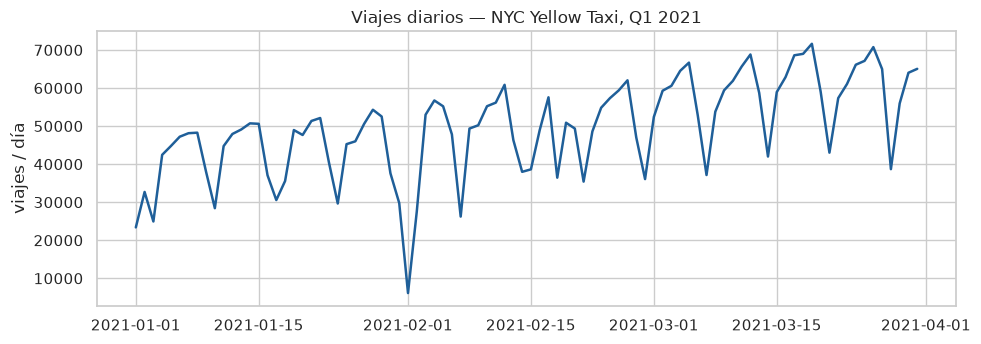

In [13]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
sns.set_theme(style="whitegrid", palette="deep")

daily = spark.sql("SELECT pickup_date, COUNT(*) AS viajes FROM trips GROUP BY 1 ORDER BY 1").toPandas()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(pd.to_datetime(daily.pickup_date), daily.viajes, color="#1f5f99", lw=1.8)
ax.set_title("Viajes diarios — NYC Yellow Taxi, Q1 2021"); ax.set_ylabel("viajes / día"); ax.set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "01_viajes_diarios.png", dpi=150); plt.show()

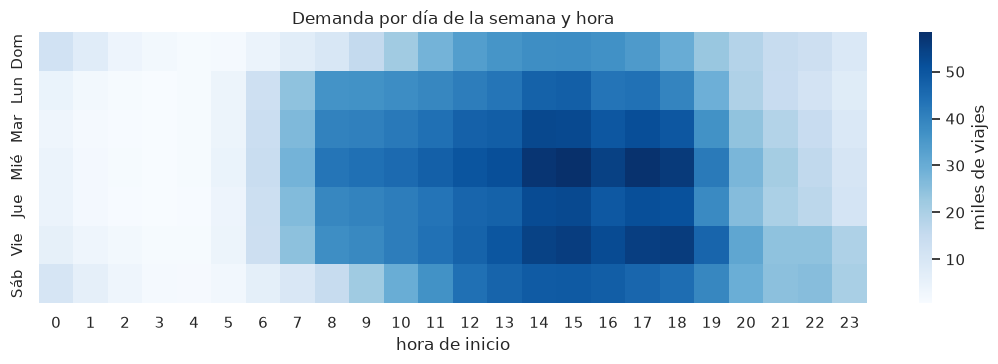

In [14]:
hp = gold_hourly.toPandas()
dow_names = {1: "Dom", 2: "Lun", 3: "Mar", 4: "Mié", 5: "Jue", 6: "Vie", 7: "Sáb"}
piv = hp.pivot(index="pickup_dow", columns="pickup_hour", values="trips").rename(index=dow_names)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(piv / 1000, cmap="Blues", ax=ax, cbar_kws={"label": "miles de viajes"})
ax.set_title("Demanda por día de la semana y hora"); ax.set_xlabel("hora de inicio"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(FIG / "02_heatmap_demanda.png", dpi=150); plt.show()

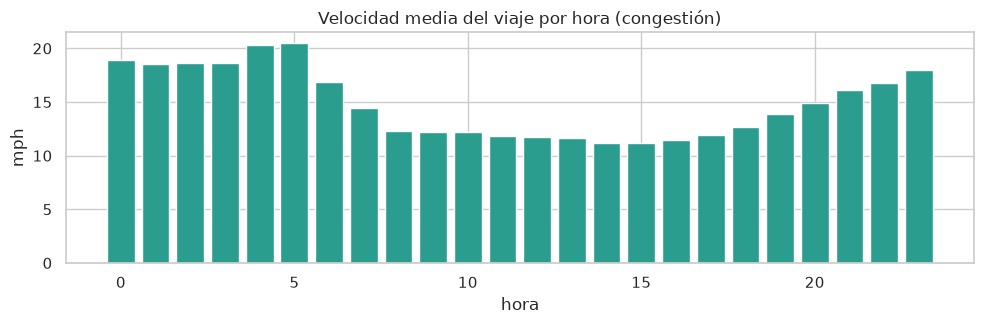

In [15]:
sp = hp.groupby("pickup_hour").apply(lambda g: np.average(g.avg_speed_mph, weights=g.trips)).reset_index(name="vel")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(sp.pickup_hour, sp.vel, color="#2a9d8f")
ax.set_title("Velocidad media del viaje por hora (congestión)"); ax.set_xlabel("hora"); ax.set_ylabel("mph")
fig.tight_layout(); fig.savefig(FIG / "03_velocidad_hora.png", dpi=150); plt.show()

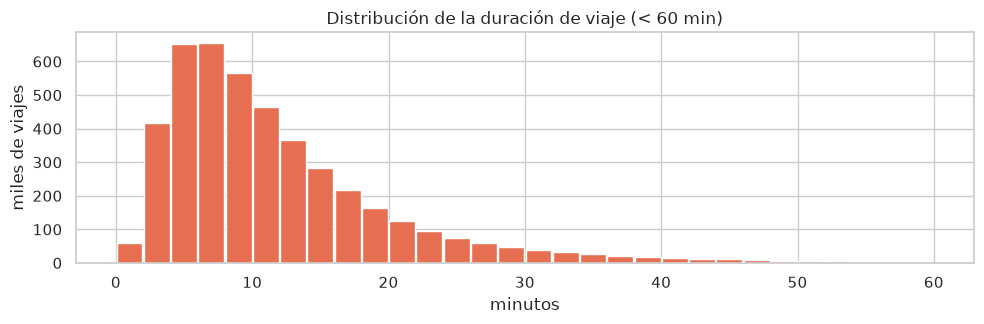

In [16]:
# Histograma distribuido: los "bins" se calculan en Spark, no en pandas
hist = spark.sql("""
SELECT FLOOR(trip_duration_min/2)*2 AS bin, COUNT(*) AS n FROM trips
WHERE trip_duration_min < 60 GROUP BY 1 ORDER BY 1""").toPandas()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(hist.bin + 1, hist.n / 1000, width=1.9, color="#e76f51")
ax.set_title("Distribución de la duración de viaje (< 60 min)"); ax.set_xlabel("minutos"); ax.set_ylabel("miles de viajes")
fig.tight_layout(); fig.savefig(FIG / "04_hist_duracion.png", dpi=150); plt.show()

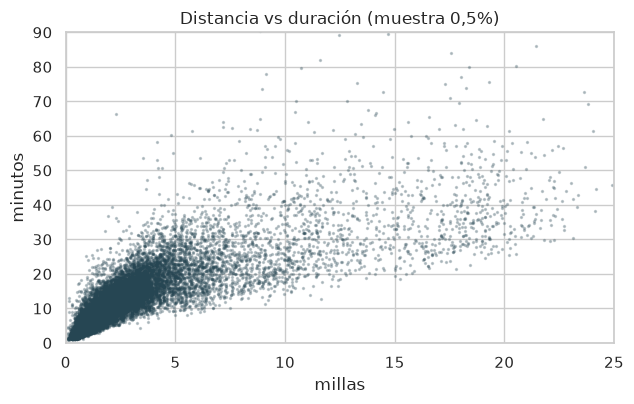

In [17]:
smp = silver.select("trip_distance", "trip_duration_min").sample(0.005, seed=SEED).toPandas()
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(smp.trip_distance, smp.trip_duration_min, s=2, alpha=0.25, color="#264653")
ax.set_xlim(0, 25); ax.set_ylim(0, 90)
ax.set_title("Distancia vs duración (muestra 0,5%)"); ax.set_xlabel("millas"); ax.set_ylabel("minutos")
fig.tight_layout(); fig.savefig(FIG / "05_dist_vs_dur.png", dpi=150); plt.show()

## 6. Modelo predictivo distribuido: ETA (duración del viaje) con `pyspark.ml`

* **Validación temporal formal:** entrenamiento con enero–febrero, prueba con **marzo completo** (datos nunca vistos, simula producción).
* **Preprocesamiento en Pipeline:** `Imputer` (nulos en pasajeros/tarifa), `StringIndexer` + `OneHotEncoder` (categóricas), `VectorAssembler`.
* **Modelos:** Regresión Lineal (línea base) vs **Gradient-Boosted Trees**, con ajuste de hiperparámetros por **validación cruzada (3-fold)**.
* **Métricas:** RMSE, MAE, R².

In [18]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

LABEL = "trip_duration_min"
data = (silver
        .withColumn("passenger_count_d", F.col("passenger_count").cast("double"))
        .withColumn("ratecode", F.coalesce(F.col("RatecodeID"), F.lit(99)).cast("string"))
        .withColumn("pu_borough", F.coalesce("pu_borough", F.lit("Unknown")))
        .withColumn("do_borough", F.coalesce("do_borough", F.lit("Unknown")))
        .withColumn("PU", F.col("PULocationID").cast("string"))
        .withColumn("DO", F.col("DOLocationID").cast("string"))
        .select(LABEL, "month", "trip_distance", "passenger_count_d", "pickup_hour", "pickup_dow",
                "is_weekend", "is_airport", "same_borough", "ratecode", "pu_borough", "do_borough", "PU", "DO"))

train_full = data.filter("month IN (1, 2)")
test = data.filter("month = 3")
# Muestra estratificada aleatoria para respetar el Free Tier de Colab (≈12 GB RAM, 2 vCPU).
TRAIN_FRACTION = float(os.environ.get("TRAIN_FRACTION", "0.25"))
train = train_full.sample(TRAIN_FRACTION, seed=SEED).cache()
METRICS["ml_rows_train"], METRICS["ml_rows_test"] = train.count(), test.count()
print(f"train: {METRICS['ml_rows_train']:,} filas | test (marzo): {METRICS['ml_rows_test']:,} filas")

cats = ["ratecode", "pu_borough", "do_borough", "PU", "DO"]
imputer = Imputer(inputCols=["passenger_count_d"], outputCols=["passenger_imp"], strategy="median")
indexers = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in cats]
ohe = OneHotEncoder(inputCols=[c + "_idx" for c in cats], outputCols=[c + "_ohe" for c in cats], handleInvalid="keep")
num = ["trip_distance", "passenger_imp", "pickup_hour", "pickup_dow", "is_weekend", "is_airport", "same_borough"]
assembler = VectorAssembler(inputCols=num + [c + "_ohe" for c in cats], outputCol="features")
prep = [imputer] + indexers + [ohe, assembler]

ev_rmse = RegressionEvaluator(labelCol=LABEL, metricName="rmse")
ev_mae = RegressionEvaluator(labelCol=LABEL, metricName="mae")
ev_r2 = RegressionEvaluator(labelCol=LABEL, metricName="r2")

def evaluate(name, model, df):
    pred = model.transform(df).cache()
    m = {"rmse": round(ev_rmse.evaluate(pred), 3), "mae": round(ev_mae.evaluate(pred), 3), "r2": round(ev_r2.evaluate(pred), 4)}
    print(f"{name:<28} RMSE={m['rmse']:.3f}  MAE={m['mae']:.3f}  R²={m['r2']:.4f}")
    return m, pred

# Línea base ingenua: predecir siempre la media de entrenamiento
mean_dur = train.agg(F.avg(LABEL)).first()[0]
naive = test.withColumn("prediction", F.lit(mean_dur))
METRICS["model_naive"] = {"rmse": round(ev_rmse.evaluate(naive), 3), "mae": round(ev_mae.evaluate(naive), 3), "r2": 0.0}
print(f"{'Línea base (media)':<28} RMSE={METRICS['model_naive']['rmse']:.3f}  MAE={METRICS['model_naive']['mae']:.3f}")

train: 655,743 filas | test (marzo): 1,847,858 filas


Línea base (media)           RMSE=9.588  MAE=6.553


In [19]:
t0 = time.time()
lr_model = Pipeline(stages=prep + [LinearRegression(labelCol=LABEL, regParam=0.01, elasticNetParam=0.0)]).fit(train)
METRICS["model_lr"], _ = evaluate("Regresión lineal", lr_model, test)
METRICS["model_lr"]["train_s"] = round(time.time() - t0, 1)

Regresión lineal             RMSE=4.998  MAE=3.238  R²=0.7278


In [20]:
# Ajuste de hiperparámetros del GBT con validación cruzada 3-fold sobre una sub-muestra
gbt = GBTRegressor(labelCol=LABEL, featuresCol="features", seed=SEED, maxBins=64, subsamplingRate=0.8)
grid = (ParamGridBuilder()
        .addGrid(gbt.maxDepth, [4, 6])
        .addGrid(gbt.maxIter, [20, 40])
        .build())
prep_model = Pipeline(stages=prep).fit(train)              # el preprocesamiento se ajusta una sola vez
cv_sample = prep_model.transform(train.sample(0.2, seed=SEED)).select("features", LABEL).cache()
t0 = time.time()
cv = CrossValidator(estimator=gbt, estimatorParamMaps=grid, evaluator=ev_rmse, numFolds=3, seed=SEED, parallelism=2)
cv_model = cv.fit(cv_sample)
cv_res = [{"maxDepth": p[gbt.maxDepth], "maxIter": p[gbt.maxIter], "cv_rmse": round(r, 3)}
          for p, r in zip(grid, cv_model.avgMetrics)]
best = min(cv_res, key=lambda r: r["cv_rmse"])
METRICS["cv_results"], METRICS["cv_best"], METRICS["cv_s"] = cv_res, best, round(time.time() - t0, 1)
print(pd.DataFrame(cv_res).sort_values("cv_rmse"))
print("Mejores hiperparámetros:", best)

   maxDepth  maxIter  cv_rmse
3         6       40    4.332
1         4       40    4.347
2         6       20    4.369
0         4       20    4.400
Mejores hiperparámetros: {'maxDepth': 6, 'maxIter': 40, 'cv_rmse': np.float64(4.332)}


In [21]:
t0 = time.time()
gbt_best = GBTRegressor(labelCol=LABEL, featuresCol="features", seed=SEED, maxBins=64, subsamplingRate=0.8,
                        maxDepth=best["maxDepth"], maxIter=best["maxIter"])
gbt_model = Pipeline(stages=prep + [gbt_best]).fit(train)
train_s = time.time() - t0
METRICS["model_gbt"], pred = evaluate("GBT (mejor por CV)", gbt_model, test)
METRICS["model_gbt"]["train_s"] = round(train_s, 1)
METRICS["model_gbt_train_metrics"], _ = evaluate("GBT — sobre train", gbt_model, train)   # chequeo de sobreajuste

GBT (mejor por CV)           RMSE=4.157  MAE=2.465  R²=0.8118


GBT — sobre train            RMSE=4.102  MAE=2.486  R²=0.8023


### Interpretación del modelo

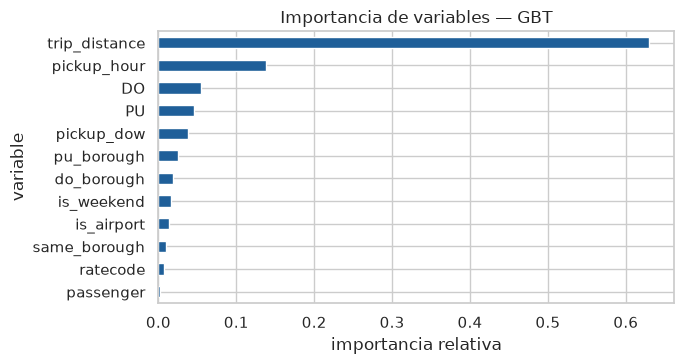

variable
trip_distance    0.630305
pickup_hour      0.138674
DO               0.054611
PU               0.045560
pickup_dow       0.038193
pu_borough       0.025190
do_borough       0.018736
is_weekend       0.016228
is_airport       0.013730
same_borough     0.009589
ratecode         0.007468
passenger        0.001716
Name: imp, dtype: float64

In [22]:
# Importancia de variables agregada por variable original (suma de sus columnas one-hot)
attrs = [a for group in pred.schema["features"].metadata["ml_attr"]["attrs"].values() for a in group]
names = {a["idx"]: a["name"] for a in attrs}
imp = gbt_model.stages[-1].featureImportances.toArray()
fi = pd.DataFrame({"feature": [names[i] for i in range(len(imp))], "imp": imp})
fi["variable"] = fi.feature.str.replace(r"_ohe_.*", "", regex=True).str.replace("_imp", "")
fi_agg = fi.groupby("variable").imp.sum().sort_values(ascending=False)
METRICS["feature_importance"] = fi_agg.round(4).to_dict()
fig, ax = plt.subplots(figsize=(7, 3.8))
fi_agg.iloc[::-1].plot.barh(ax=ax, color="#1f5f99")
ax.set_title("Importancia de variables — GBT"); ax.set_xlabel("importancia relativa")
fig.tight_layout(); fig.savefig(FIG / "06_importancia_variables.png", dpi=150); plt.show()
fi_agg

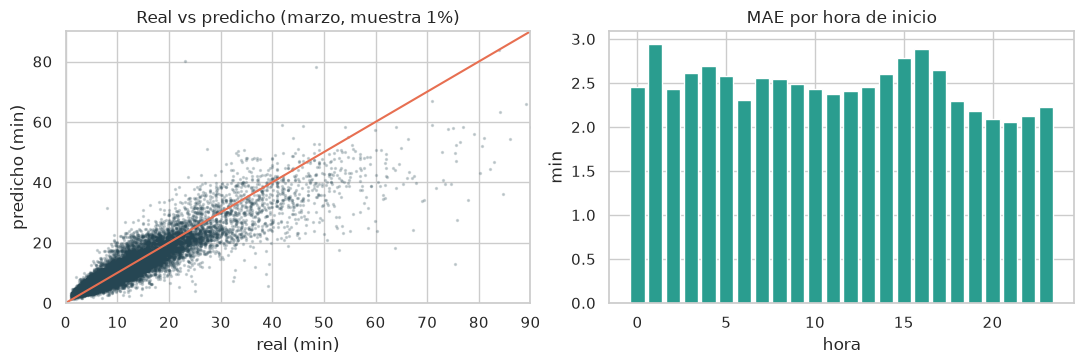

Viajes de marzo con ETA dentro de ±5 min: 88.7%


In [23]:
# Error por hora del día: ¿dónde falla el ETA?
err_h = (pred.withColumn("abs_err", F.abs(F.col("prediction") - F.col(LABEL)))
         .groupBy("pickup_hour").agg(F.avg("abs_err").alias("mae"), F.count("*").alias("n"))
         .orderBy("pickup_hour").toPandas())
METRICS["mae_by_hour"] = err_h.round(3).to_dict(orient="records")
cmp = pred.select(LABEL, "prediction").sample(0.01, seed=SEED).toPandas()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].scatter(cmp[LABEL], cmp.prediction, s=2, alpha=0.2, color="#264653")
axs[0].plot([0, 90], [0, 90], color="#e76f51", lw=1.5); axs[0].set_xlim(0, 90); axs[0].set_ylim(0, 90)
axs[0].set_title("Real vs predicho (marzo, muestra 1%)"); axs[0].set_xlabel("real (min)"); axs[0].set_ylabel("predicho (min)")
axs[1].bar(err_h.pickup_hour, err_h.mae, color="#2a9d8f")
axs[1].set_title("MAE por hora de inicio"); axs[1].set_xlabel("hora"); axs[1].set_ylabel("min")
fig.tight_layout(); fig.savefig(FIG / "07_real_vs_pred.png", dpi=150); plt.show()

within5 = pred.select((F.abs(F.col("prediction") - F.col(LABEL)) <= 5).cast("int").alias("ok")).agg(F.avg("ok")).first()[0]
METRICS["pct_within_5min"] = round(100 * within5, 2)
print(f"Viajes de marzo con ETA dentro de ±5 min: {100*within5:.1f}%")

In [24]:
# Persistencia del modelo en el Data Lake (versionado por fecha) para servirlo después
model_path = LAKE / "models" / f"gbt_eta_{time.strftime('%Y%m%d')}"
gbt_model.write().overwrite().save(str(model_path))
print("Modelo guardado en", model_path)

Modelo guardado en /home/claude/lake/models/gbt_eta_20261019


## 7. Data Warehouse en BigQuery (Sandbox gratuito) + BigQuery ML

**Gobierno y permisos:** la autenticación usa OAuth de la cuenta Google (`auth.authenticate_user()`); el ID del proyecto se lee
desde *Secretos de Colab* (no queda en el código). En producción se usaría una **cuenta de servicio** con mínimo privilegio:
`roles/bigquery.dataEditor` (sobre el dataset) + `roles/bigquery.jobUser` (sobre el proyecto).

Esta sección se ejecuta solo en Colab y si `GCP_PROJECT_ID` está configurado.

In [25]:
GCP_PROJECT_ID = os.environ.get("GCP_PROJECT_ID", "")      # o completar aquí: "mi-proyecto-123"
if IN_COLAB and not GCP_PROJECT_ID:
    try:
        from google.colab import userdata
        GCP_PROJECT_ID = userdata.get("GCP_PROJECT_ID")
    except Exception:
        pass
RUN_BQ = IN_COLAB and bool(GCP_PROJECT_ID)
print("Ejecutar BigQuery:", RUN_BQ)

if RUN_BQ:
    from google.colab import auth
    from google.cloud import bigquery
    auth.authenticate_user()                                     # credenciales IAM del usuario
    bq = bigquery.Client(project=GCP_PROJECT_ID)
    DS = f"{GCP_PROJECT_ID}.nyc_taxi"
    bq.create_dataset(bigquery.Dataset(DS), exists_ok=True)       # location por defecto: US (multi-región)

    # Carga de la zona SILVER (Parquet) en una tabla particionada por mes (rango entero) y clusterizada.
    # Nota: en el Sandbox las particiones por FECHA expiran a los 60 días de su fecha -> datos de 2021 se
    # borrarían al instante. Por eso se usa partición por RANGO ENTERO sobre `month` (no expira).
    job_cfg = bigquery.LoadJobConfig(
        source_format=bigquery.SourceFormat.PARQUET,
        write_disposition="WRITE_TRUNCATE",
        range_partitioning=bigquery.RangePartitioning(field="month", range_=bigquery.PartitionRange(start=1, end=13, interval=1)),
        clustering_fields=["pickup_date", "pu_borough", "do_borough"])
    cols = ["pickup_date", "tpep_pickup_datetime", "pickup_hour", "pickup_dow", "is_weekend", "trip_distance",
            "trip_duration_min", "passenger_count", "RatecodeID", "payment_type", "fare_amount", "tip_amount",
            "total_amount", "tip_pct", "pu_borough", "do_borough", "pu_zone", "do_zone", "is_airport", "month"]
    tmp = Path("/content/bq_stage"); tmp.mkdir(exist_ok=True)
    silver.select(cols).coalesce(4).write.mode("overwrite").parquet(str(tmp / "trips"))
    first = True
    for f in sorted((tmp / "trips").glob("*.parquet")):
        job_cfg.write_disposition = "WRITE_TRUNCATE" if first else "WRITE_APPEND"
        with open(f, "rb") as fh:
            bq.load_table_from_file(fh, f"{DS}.trips", job_config=job_cfg).result()
        first = False
    print("Filas en BigQuery:", bq.get_table(f"{DS}.trips").num_rows)

Ejecutar BigQuery: False


In [26]:
if RUN_BQ:
    q = f"""
    SELECT pu_borough, COUNT(*) AS viajes, ROUND(AVG(trip_duration_min),2) AS dur_media,
           ROUND(APPROX_QUANTILES(fare_amount, 100)[OFFSET(50)],2) AS tarifa_mediana
    FROM `{DS}.trips`
    WHERE month = 3                                              -- partition pruning
    GROUP BY pu_borough ORDER BY viajes DESC"""
    job = bq.query(q)
    display(job.to_dataframe())
    print(f"Bytes procesados: {job.total_bytes_processed/1e6:.1f} MB (gracias a la partición por mes)")

In [27]:
if RUN_BQ:
    # BigQuery ML: clasificación ¿el pasajero deja propina ≥ 20%? (solo pagos con tarjeta, donde la propina se registra)
    bq.query(f"""
    CREATE OR REPLACE MODEL `{DS}.tip_model`
    OPTIONS(model_type='logistic_reg', input_label_cols=['good_tip'],
            data_split_method='CUSTOM', data_split_col='is_eval', auto_class_weights=TRUE) AS
    SELECT IF(tip_pct >= 0.2, 1, 0) AS good_tip, trip_distance, pickup_hour, pickup_dow, is_airport,
           pu_borough, do_borough, CAST(passenger_count AS STRING) AS passengers,
           month = 2 AS is_eval
    FROM `{DS}.trips` WHERE payment_type = 1 AND month IN (1, 2)""").result()
    ev = bq.query(f"SELECT * FROM ML.EVALUATE(MODEL `{DS}.tip_model`)").to_dataframe()
    display(ev)
    METRICS["bqml_tip_model"] = ev.round(4).iloc[0].to_dict()

## 8. Resumen de resultados

In [28]:
METRICS["spark_version"] = spark.version
with open(OUT / "metrics.json", "w") as fh:
    json.dump(METRICS, fh, indent=2, default=str, ensure_ascii=False)
summary = pd.DataFrame({k: METRICS[k] for k in ["model_naive", "model_lr", "model_gbt"]}).T
summary.index = ["Línea base (media)", "Regresión lineal", "GBT (CV)"]
print(summary[["rmse", "mae", "r2"]])
print(f"\nMejora del GBT vs línea base en RMSE: "
      f"{100*(1-METRICS['model_gbt']['rmse']/METRICS['model_naive']['rmse']):.1f}%")
print("Métricas guardadas en", OUT / "metrics.json")

                     rmse    mae      r2
Línea base (media)  9.588  6.553  0.0000
Regresión lineal    4.998  3.238  0.7278
GBT (CV)            4.157  2.465  0.8118

Mejora del GBT vs línea base en RMSE: 56.6%
Métricas guardadas en /home/claude/repo/results/metrics.json
